<a href="https://colab.research.google.com/github/Adi2618/AIML/blob/main/AIML_lab1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

from imblearn.over_sampling import RandomOverSampler

In [ ]:
#1
import pandas as pd

url = "https://raw.githubusercontent.com/Yrzxiong/Bitcoin-Dataset/master/bitcoin_dataset.csv"
df = pd.read_csv(url)

df.info()
df.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2906 entries, 0 to 2905
Data columns (total 24 columns):
 #   Column                                               Non-Null Count  Dtype  
---  ------                                               --------------  -----  
 0   Date                                                 2906 non-null   object 
 1   btc_market_price                                     2906 non-null   float64
 2   btc_total_bitcoins                                   2879 non-null   float64
 3   btc_market_cap                                       2906 non-null   float64
 4   btc_trade_volume                                     2885 non-null   float64
 5   btc_blocks_size                                      2877 non-null   float64
 6   btc_avg_block_size                                   2906 non-null   float64
 7   btc_n_orphaned_blocks                                2906 non-null   int64  
 8   btc_n_transactions_per_block                         2906 non-null  

,Date,btc_market_price,btc_total_bitcoins,btc_market_cap,btc_trade_volume,btc_blocks_size,btc_avg_block_size,btc_n_orphaned_blocks,btc_n_transactions_per_block,btc_median_confirmation_time,...,btc_cost_per_transaction_percent,btc_cost_per_transaction,btc_n_unique_addresses,btc_n_transactions,btc_n_transactions_total,btc_n_transactions_excluding_popular,btc_n_transactions_excluding_chains_longer_than_100,btc_output_volume,btc_estimated_transaction_volume,btc_estimated_transaction_volume_usd
0,2/17/2010 0:00,0.0,2043200.0,0.0,0.0,0.0,0.000235,0,1.0,0.0,...,31.781022,0.0,241,244,41240,244,244,65173.13,36500.0,0.0
1,2/18/2010 0:00,0.0,2054650.0,0.0,0.0,0.0,0.000241,0,1.0,0.0,...,154.463801,0.0,234,235,41475,235,235,18911.74,7413.0,0.0
2,2/19/2010 0:00,0.0,2063600.0,0.0,0.0,0.0,0.000228,0,1.0,0.0,...,1278.516635,0.0,185,183,41658,183,183,9749.98,700.0,0.0
3,2/20/2010 0:00,0.0,2074700.0,0.0,0.0,0.0,0.000218,0,1.0,0.0,...,22186.687990,0.0,224,224,41882,224,224,11150.03,50.0,0.0
4,2/21/2010 0:00,0.0,2085400.0,0.0,0.0,0.0,0.000234,0,1.0,0.0,...,689.179876,0.0,218,218,42100,218,218,12266.83,1553.0,0.0


In [ ]:
#2
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

print(df.dtypes)

print(df.isnull().sum())

Rows: 2906
Columns: 24
Date                                                    object
btc_market_price                                       float64
btc_total_bitcoins                                     float64
btc_market_cap                                         float64
btc_trade_volume                                       float64
btc_blocks_size                                        float64
btc_avg_block_size                                     float64
btc_n_orphaned_blocks                                    int64
btc_n_transactions_per_block                           float64
btc_median_confirmation_time                           float64
btc_hash_rate                                          float64
btc_difficulty                                         float64
btc_miners_revenue                                     float64
btc_transaction_fees                                   float64
btc_cost_per_transaction_percent                       float64
btc_cost_per_transaction        

In [ ]:
#3
df.head()

df.tail()

df.sample(5)

,Date,btc_market_price,btc_total_bitcoins,btc_market_cap,btc_trade_volume,btc_blocks_size,btc_avg_block_size,btc_n_orphaned_blocks,btc_n_transactions_per_block,btc_median_confirmation_time,...,btc_cost_per_transaction_percent,btc_cost_per_transaction,btc_n_unique_addresses,btc_n_transactions,btc_n_transactions_total,btc_n_transactions_excluding_popular,btc_n_transactions_excluding_chains_longer_than_100,btc_output_volume,btc_estimated_transaction_volume,btc_estimated_transaction_volume_usd
1165,4/27/2013 0:00,128.00001,11086050.0,1.419015e+09,9.815662e+06,7165.0,0.148059,0,397.0,7.200000,...,1.816970,10.639959,62711,48325,16850263,24689,25672,893994.839,221082.0,28298545.0
1031,12/14/2012 0:00,13.90119,10554875.0,1.467253e+08,1.057253e+06,3957.0,0.178214,0,342.0,19.383333,...,1.100211,0.883831,33491,41397,9886097,15409,15122,3494315.456,239227.0,3325538.0
2172,1/29/2016 0:00,377.26000,15141050.0,5.712113e+09,5.431243e+07,56637.0,0.663735,0,1149.0,7.050000,...,1.101496,7.278399,424226,222622,106670836,213749,113560,6544542.321,389924.0,147102840.0
1733,11/16/2014 0:00,383.65000,13507625.0,5.182200e+09,1.111226e+07,25580.0,0.308625,1,698.0,8.300000,...,2.953006,19.020854,220218,73338,51578514,67707,39111,696352.429,123129.0,47238357.0
782,4/9/2012 0:00,4.80000,8748850.0,4.199448e+07,2.084595e+05,898.0,0.018035,0,59.0,8.666667,...,2.919787,5.997419,10799,6045,2788761,4610,5364,1580081.103,258683.0,1241680.0


In [ ]:
#4
df = df.fillna(df.median(numeric_only=True))

print(df.isnull().sum())


Date                                                   0
btc_market_price                                       0
btc_total_bitcoins                                     0
btc_market_cap                                         0
btc_trade_volume                                       0
btc_blocks_size                                        0
btc_avg_block_size                                     0
btc_n_orphaned_blocks                                  0
btc_n_transactions_per_block                           0
btc_median_confirmation_time                           0
btc_hash_rate                                          0
btc_difficulty                                         0
btc_miners_revenue                                     0
btc_transaction_fees                                   0
btc_cost_per_transaction_percent                       0
btc_cost_per_transaction                               0
btc_n_unique_addresses                                 0
btc_n_transactions             

In [ ]:
#5
print("Duplicate Rows:", df.duplicated().sum())

df = df.drop_duplicates()

print("After Removal:", df.duplicated().sum())

Duplicate Rows: 0
After Removal: 0


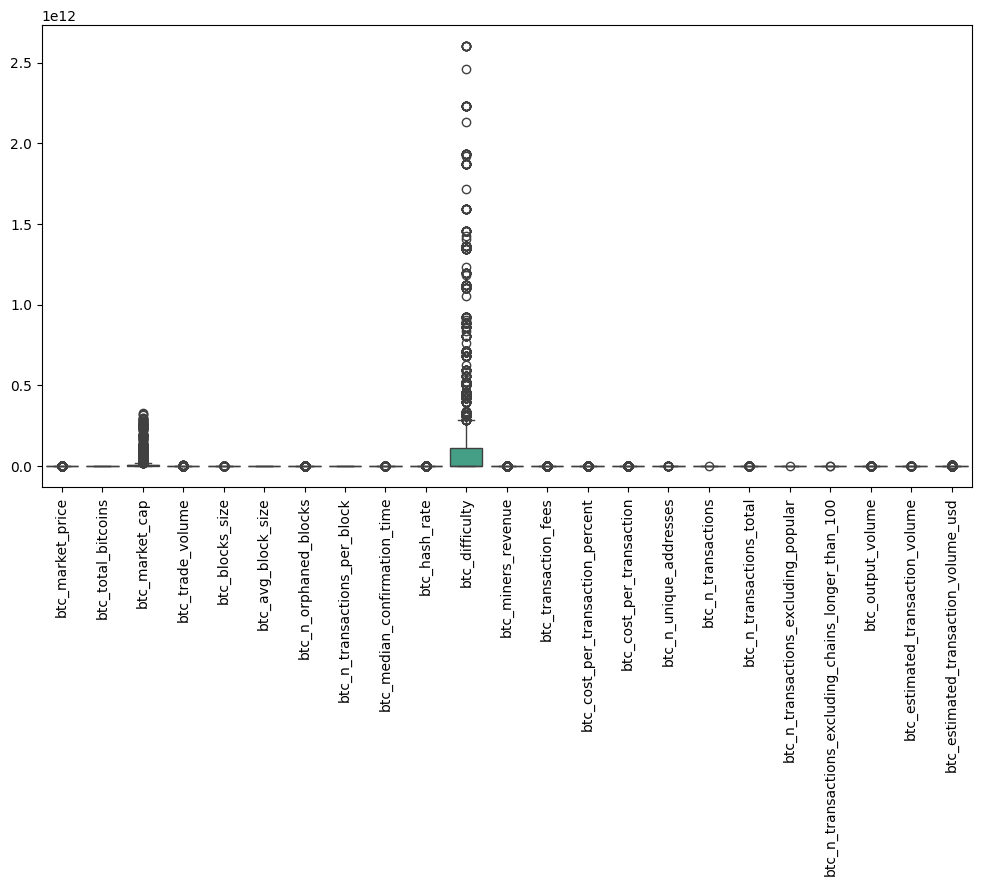

In [ ]:
#6
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12,6))
sns.boxplot(data=df.select_dtypes(include=['int64','float64']))
plt.xticks(rotation=90)
plt.show()

In [ ]:
#7
Q1 = df.select_dtypes(include=['int64','float64']).quantile(0.25)
Q3 = df.select_dtypes(include=['int64','float64']).quantile(0.75)

IQR = Q3 - Q1

df = df[~((df.select_dtypes(include=['int64','float64']) < (Q1 - 1.5*IQR)) |
          (df.select_dtypes(include=['int64','float64']) > (Q3 + 1.5*IQR))).any(axis=1)]

In [ ]:
#8
import pandas as pd

url = "https://raw.githubusercontent.com/Yrzxiong/Bitcoin-Dataset/master/bitcoin_dataset.csv"
df = pd.read_csv(url)
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
df["Date_Label"] = le.fit_transform(df["Date"])

df.head()

#One Hot Encoding
df["Date"] = pd.to_datetime(df["Date"])

df["Month"] = df["Date"].dt.month

df = pd.get_dummies(df, columns=["Month"], prefix="Month")

df.head()

,Date,btc_market_price,btc_total_bitcoins,btc_market_cap,btc_trade_volume,btc_blocks_size,btc_avg_block_size,btc_n_orphaned_blocks,btc_n_transactions_per_block,btc_median_confirmation_time,...,Month_3,Month_4,Month_5,Month_6,Month_7,Month_8,Month_9,Month_10,Month_11,Month_12
0,2010-02-17,0.0,2043200.0,0.0,0.0,0.0,0.000235,0,1.0,0.0,...,False,False,False,False,False,False,False,False,False,False
1,2010-02-18,0.0,2054650.0,0.0,0.0,0.0,0.000241,0,1.0,0.0,...,False,False,False,False,False,False,False,False,False,False
2,2010-02-19,0.0,2063600.0,0.0,0.0,0.0,0.000228,0,1.0,0.0,...,False,False,False,False,False,False,False,False,False,False
3,2010-02-20,0.0,2074700.0,0.0,0.0,0.0,0.000218,0,1.0,0.0,...,False,False,False,False,False,False,False,False,False,False
4,2010-02-21,0.0,2085400.0,0.0,0.0,0.0,0.000234,0,1.0,0.0,...,False,False,False,False,False,False,False,False,False,False


In [ ]:
#9
#Min Max Normalization
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

numeric = df.select_dtypes(include=['int64','float64']).columns

df[numeric] = scaler.fit_transform(df[numeric])

#Standardization
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

df[numeric] = scaler.fit_transform(df[numeric])

In [ ]:
#10
corr = df.corr(numeric_only=True)

print(corr["btc_market_price"].sort_values(ascending=False))

btc_market_price                    1.000000
btc_market_cap                      0.995798
btc_n_transactions_total            0.947332
btc_blocks_size                     0.941470
btc_n_unique_addresses              0.938862
                                      ...   
Date_9/29/2010 0:00                -0.022792
Date_10/3/2010 0:00                -0.022793
Date_7/3/2010 0:00                 -0.022801
btc_cost_per_transaction_percent   -0.543032
btc_n_orphaned_blocks                    NaN
Name: btc_market_price, Length: 1184, dtype: float64


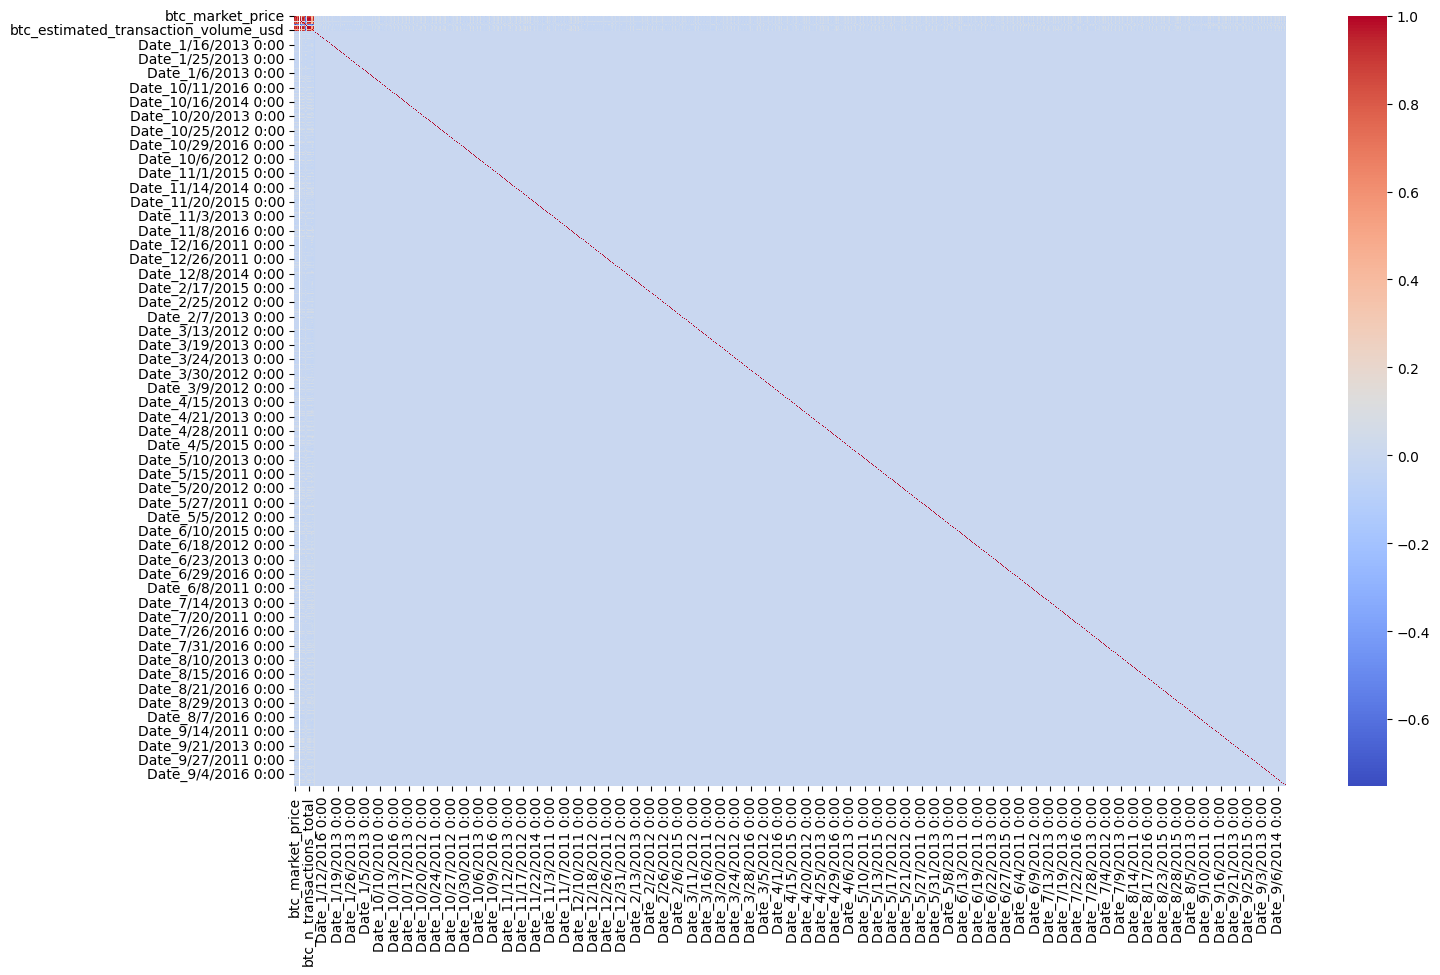

In [ ]:
#11
plt.figure(figsize=(16,10))

sns.heatmap(df.corr(numeric_only=True), cmap="coolwarm")

plt.show()

In [ ]:
#12
df["Price_per_Transaction"] = df["btc_market_price"] / df["btc_n_transactions"]

df["Revenue_per_Block"] = df["btc_miners_revenue"] / (df["btc_avg_block_size"] + 1)

In [ ]:
#13
df["Date"] = pd.to_datetime(df["Date"])

df["btc_n_transactions"] = df["btc_n_transactions"].astype(float)

print(df.dtypes)

Date                                                   datetime64[ns]
btc_market_price                                              float64
btc_total_bitcoins                                            float64
btc_market_cap                                                float64
btc_trade_volume                                              float64
btc_blocks_size                                               float64
btc_avg_block_size                                            float64
btc_n_orphaned_blocks                                           int64
btc_n_transactions_per_block                                  float64
btc_median_confirmation_time                                  float64
btc_hash_rate                                                 float64
btc_difficulty                                                float64
btc_miners_revenue                                            float64
btc_transaction_fees                                          float64
btc_cost_per_transac

In [ ]:
#14
df.columns = df.columns.str.strip()

df = df.fillna(method="ffill")

/tmp/ipykernel_4633/3303098654.py:4: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  df = df.fillna(method="ffill")


In [ ]:
#15
from sklearn.model_selection import train_test_split

X = df.drop(columns=["btc_market_price"])

X = X.select_dtypes(include=['int64','float64'])

y = df["btc_market_price"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [ ]:
#16
from imblearn.over_sampling import RandomOverSampler

df["Target"] = (df["btc_market_price"] > df["btc_market_price"].median()).astype(int)

X = df.select_dtypes(include=['int64','float64']).drop(columns=["Target"])

y = df["Target"]

ros = RandomOverSampler(random_state=42)

X_resampled, y_resampled = ros.fit_resample(X, y)

print(y_resampled.value_counts())

Target
0    1454
1    1454
Name: count, dtype: int64


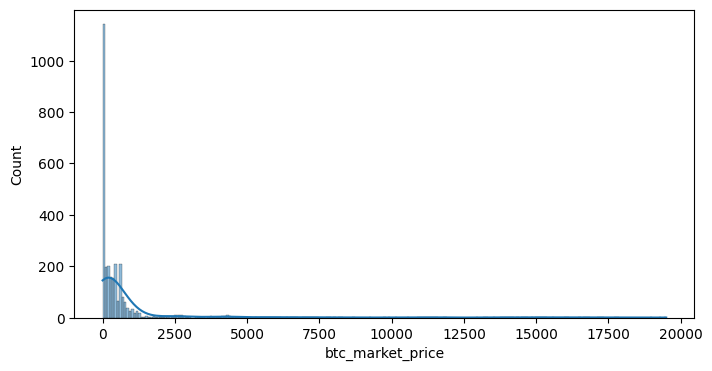

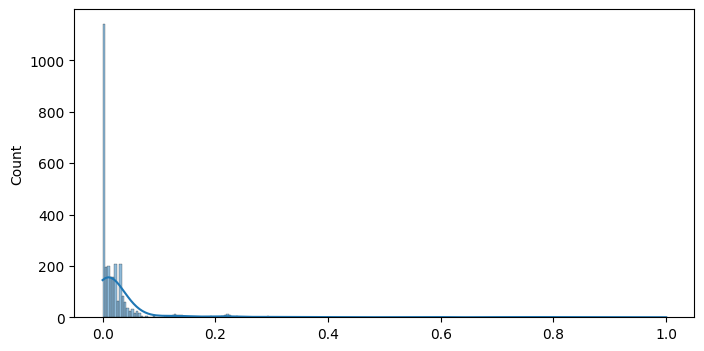

In [ ]:
#17
plt.figure(figsize=(8,4))
sns.histplot(df["btc_market_price"], kde=True)
plt.show()

from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

scaled = scaler.fit_transform(df[["btc_market_price"]])

plt.figure(figsize=(8,4))
sns.histplot(scaled.flatten(), kde=True)
plt.show()

In [ ]:
#18
original = pd.read_csv(url)

print("Original Shape:", original.shape)

print("Processed Shape:", df.shape)

print(original.head())

print(df.head())

Original Shape: (2906, 24)
Processed Shape: (2906, 38)
             Date  btc_market_price  btc_total_bitcoins  btc_market_cap  \
0  2/17/2010 0:00               0.0           2043200.0             0.0   
1  2/18/2010 0:00               0.0           2054650.0             0.0   
2  2/19/2010 0:00               0.0           2063600.0             0.0   
3  2/20/2010 0:00               0.0           2074700.0             0.0   
4  2/21/2010 0:00               0.0           2085400.0             0.0   

   btc_trade_volume  btc_blocks_size  btc_avg_block_size  \
0               0.0              0.0            0.000235   
1               0.0              0.0            0.000241   
2               0.0              0.0            0.000228   
3               0.0              0.0            0.000218   
4               0.0              0.0            0.000234   

   btc_n_orphaned_blocks  btc_n_transactions_per_block  \
0                      0                           1.0   
1                

In [ ]:
df.to_csv("bitcoin_preprocessed.csv", index=False)

print("Dataset Saved Successfully")

Dataset Saved Successfully


In [ ]:
print("Data Preprocessing Completed Successfully")

Data Preprocessing Completed Successfully
